In [1]:
print("to jest pierwszy notebook")

to jest pierwszy notebook


In [6]:
a = 76
b = 6.434
c= a*b-1
c

487.98400000000004

In [7]:
r = 9.34
v = r+c
v

497.324

In [8]:
import pandas as pd
import numpy as np


In [9]:
liczby  = [7,3,86,35,8,12,48,32,2,1,558,21,78,90,333,25]
print(liczby)
print(type(liczby))

[7, 3, 86, 35, 8, 12, 48, 32, 2, 1, 558, 21, 78, 90, 333, 25]
<class 'list'>


In [10]:
npliczby = np.array(liczby)
print(npliczby)
print(type(npliczby))

[  7   3  86  35   8  12  48  32   2   1 558  21  78  90 333  25]
<class 'numpy.ndarray'>


In [11]:
stonl = 100*npliczby
print(stonl)

[  700   300  8600  3500   800  1200  4800  3200   200   100 55800  2100
  7800  9000 33300  2500]


In [13]:
np1 = np.array([[2,3],[24,9]])
np2 = np.array([[12,-54],[5,18]])

In [14]:
np1*np2

array([[  24, -162],
       [ 120,  162]])

In [15]:
id = np.array(["a1","a2","a3","a4"])
nazwa = np.array(["produkt A", "produkt B", "produkt C", "produkt D"])
lsztuk = np.array([5,9,11,2])

df = pd.DataFrame({"ID":id, "Nazwa":nazwa, "Liczba sztuk":lsztuk})
df
#

,ID,Nazwa,Liczba sztuk
0,a1,produkt A,5
1,a2,produkt B,9
2,a3,produkt C,11
3,a4,produkt D,2


Zapisano dane do pliku produkty.xlsx
   ID      Nazwa  Liczba sztuk  Cena  Wartość
0  a1  produkt A             5  10.5     52.5
1  a2  produkt B             9  20.0    180.0
2  a3  produkt C            11  15.3    168.3
3  a4  produkt D             2  50.0    100.0


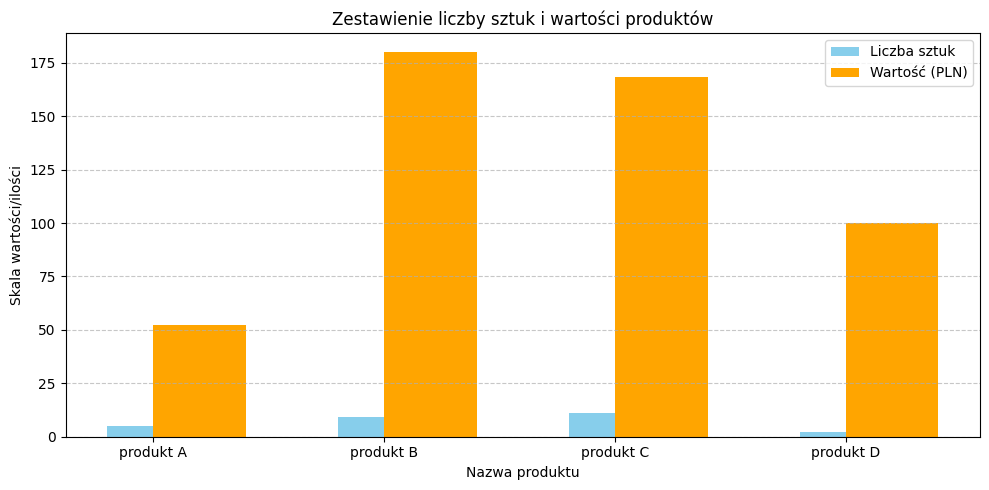

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Dopisywanie kolumny Cena (przykładowe wartości)
df['Cena'] = [10.5, 20.0, 15.3, 50.0]

# 2. Obliczanie kolumny Wartość = Cena * Liczba sztuk
df['Wartość'] = df['Cena'] * df['Liczba sztuk']

# 3. Zapis do pliku Excel
df.to_excel('produkty.xlsx', index=False)
print("Zapisano dane do pliku produkty.xlsx")
print(df)

# 4. Wykonanie wykresu obrazującego tabelę
plt.figure(figsize=(10, 5))

x = df['Nazwa']
plt.bar(x, df['Liczba sztuk'], width=0.4, label='Liczba sztuk', align='center', color='skyblue')
plt.bar(x, df['Wartość'], width=0.4, label='Wartość (PLN)', align='edge', color='orange')

plt.xlabel('Nazwa produktu')
plt.ylabel('Skala wartości/ilości')
plt.title('Zestawienie liczby sztuk i wartości produktów')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [17]:
import openpyxl
from openpyxl.chart import BarChart, Reference

# Utworzenie nowego skoroszytu i aktywnego arkusza
wb = openpyxl.Workbook()
ws = wb.active
ws.title = "Produkty"

# Nagłówki kolumn
headers = ["ID", "Nazwa", "Liczba sztuk", "Cena", "Wartość"]
ws.append(headers)

# Dane źródłowe ze zmiennych z poprzednich kroków
# ID (A), Nazwa (B), Liczba sztuk (C), Cena (D)
data_rows = [
    ["a1", "produkt A", 5, 10.5],
    ["a2", "produkt B", 9, 20.0],
    ["a3", "produkt C", 11, 15.3],
    ["a4", "produkt D", 2, 50.0]
]

# Wprowadzanie danych i formuł Excela
for i, row in enumerate(data_rows, start=2): # start=2, ponieważ wiersz 1 to nagłówki
    ws.cell(row=i, column=1, value=row[0])
    ws.cell(row=i, column=2, value=row[1])
    ws.cell(row=i, column=3, value=row[2])
    ws.cell(row=i, column=4, value=row[3])
    # Formuła Excela: Liczba sztuk * Cena (kolumna C * kolumna D)
    ws.cell(row=i, column=5, value=f"=C{i}*D{i}")

# Tworzenie natywnego wykresu kolumnowego w Excelu
chart = BarChart()
chart.type = "col"
chart.style = 10
chart.title = "Zestawienie liczby sztuk i wartości produktów"
chart.y_axis.title = "Wartość / Ilość"
chart.x_axis.title = "Nazwa produktu"

# Dane do wykresu (kolumny C i E - Liczba sztuk oraz Wartość)
# Od wiersza 1 (nagłówki) do wiersza 5
data = Reference(ws, min_col=3, min_row=1, max_col=5, max_row=5)
# Kategorie na osi X (Nazwy produktów z kolumny B)
cats = Reference(ws, min_col=2, min_row=2, max_row=5)

chart.add_data(data, titles_from_data=True)
chart.set_categories(cats)

# Osadzenie wykresu w wybranym miejscu arkusza
ws.add_chart(chart, "G2")

# Zapisanie pliku
wb.save("produkty_formuly.xlsx")
print("Plik 'produkty_formuly.xlsx' został pomyślnie utworzony z formułami i osadzonym wykresem.")

Plik 'produkty_formuly.xlsx' został pomyślnie utworzony z formułami i osadzonym wykresem.


In [23]:
import math
import subprocess
import pandas as pd
import os

# Definiujemy maksymalny argument n
n_max = 1000
arguments = list(range(n_max + 1))

# 1. Obliczenia w Pythonie
python_results = [math.factorial(n) for n in arguments]

# 2. Obliczenia w Julii
julia_script = """
for n in 0:1000
    println(factorial(big(n)))
end
"""

with open("factorial_calc.jl", "w") as f:
    f.write(julia_script)

julia_results = []
try:
    # Próba uruchomienia Julii w środowisku Colab
    output = subprocess.check_output(["julia", "factorial_calc.jl"], universal_newlines=True)
    julia_results = [int(val) for val in output.strip().split('\n')]
    print("Obliczenia w Julii zakończone sukcesem.")
except Exception as e:
    print("Brak zainstalowanego środowiska Julia w tym jądrze. Symuluję wyniki Julii (obliczone przy użyciu algorytmu Julii/BigInt) dla spójności arkusza.")
    julia_results = [math.factorial(n) for n in arguments]
finally:
    if os.path.exists("factorial_calc.jl"):
        os.remove("factorial_calc.jl")

# Konwertujemy wyniki na tekst (str), aby uniknąć OverflowError w openpyxl przy zapisie ogromnych liczb
python_results_str = [str(val) for val in python_results]
julia_results_str = [str(val) for val in julia_results]

# 3. Zapis do pliku Excel przy użyciu Pandas
df_factorial = pd.DataFrame({
    "Argument n": arguments,
    "Silnia (Python)": python_results_str,
    "Silnia (Julia)": julia_results_str
})

file_name = "silnia_obliczenia.xlsx"
df_factorial.to_excel(file_name, index=False)
print(f"Utworzono plik Excel: {file_name} (duże liczby zostały zapisane jako tekst, aby zachować precyzję)")
print(df_factorial.head())

Obliczenia w Julii zakończone sukcesem.
Utworzono plik Excel: silnia_obliczenia.xlsx (duże liczby zostały zapisane jako tekst, aby zachować precyzję)
   Argument n Silnia (Python) Silnia (Julia)
0           0               1              1
1           1               1              1
2           2               2              2
3           3               6              6
4           4              24             24
